In [1]:
print("Hi, world!")

Hi, world!


In [2]:
import os
import glob
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as T
from matplotlib.patches import Polygon

In [3]:
# --- 1. SETTINGS & PATHS ---
BASE_PATH = os.path.expanduser("~/TROGS-26/data/raw")
IMG_DIR = os.path.join(BASE_PATH, "Images")
ANN_DIR = os.path.join(BASE_PATH, "Annotations")

In [4]:
import os
import glob
import torch
from torch.utils.data import Dataset
from PIL import Image
import torchvision.transforms as T

class GreekSqueezeDataset(Dataset):
    def __init__(self, img_dir, ann_dir, transform=None):
        self.img_dir = img_dir
        self.ann_dir = ann_dir
        self.transform = transform
        
        # Identify unique samples based on Rotation1 text files
        search_pattern = os.path.join(ann_dir, "*_Rotation1_300dpi_letters.txt")
        ann_files = sorted(glob.glob(search_pattern))
        self.ids = [os.path.basename(f).replace("_Rotation1_300dpi_letters.txt", "") for f in ann_files]

    def _parse_annotations(self, file_path):
        """
        Parses the .txt format by STRICTLY mimicking make_xml.py logic.
        """
        boxes = []
        angle = 0.0
        
        if not os.path.exists(file_path):
            return boxes, [], angle
        
        # 1. Read all lines first to handle index-based logic
        with open(file_path, 'r', encoding='utf-8') as f:
            lines = f.readlines()

        transcript_start_idx = -1
        box_lines = []

        # 2. Iterate lines to find sections
        for i, line in enumerate(lines):
            line_stripped = line.strip()
            
            if line_stripped.startswith("# Baseline angle"):
                try:
                    # Angle is usually on the next line (i+1)
                    angle = float(lines[i+1].strip())
                except:
                    pass
            
            elif line_stripped.startswith("# Boxes"):
                # Boxes follow this line until # Transcript
                # We collect them now, but we don't parse them yet
                j = i + 1
                while j < len(lines):
                    if lines[j].strip().startswith("# Transcript"):
                        break
                    # Valid box lines have 8 numbers
                    parts = lines[j].strip().split()
                    if len(parts) == 8:
                        try:
                            c = [float(p) for p in parts]
                            poly = [(c[0], c[1]), (c[2], c[3]), (c[4], c[5]), (c[6], c[7])]
                            boxes.append(poly)
                        except:
                            pass
                    j += 1
            
            elif line_stripped.startswith("# Transcript"):
                transcript_start_idx = i + 1

        # 3. Parse Transcript EXACTLY like make_xml.py
        # make_xml.py reads from transcript_start_idx until the end (or max_line)
        # It treats '\n' as '$'
        
        clean_labels = []
        
        if transcript_start_idx != -1:
            for i in range(transcript_start_idx, len(lines)):
                line_content = lines[i] # Do NOT strip yet, make_xml.py reads raw line
                
                # Check if we hit the "# Lines" metadata section which might be at the end
                if line_content.strip().startswith("# Lines"):
                    break
                
                # Process strictly character by character
                for char in line_content:
                    # make_xml.py logic: if (char != "*" and char != " ")
                    if char == "*" or char == " ":
                        continue
                    
                    # make_xml.py logic: if (char == "\n"): char = "$"
                    if char == "\n" or char == "\r":
                        # In make_xml, '$' breaks the TextLine loop and DOES NOT consume a box.
                        # So we effectively ignore newlines for labeling purposes.
                        continue
                    
                    # If it's a valid char, it corresponds to a box
                    clean_labels.append(char)

        # 4. Alignment Safety
        # Truncate to the minimum length to prevent crashes if files are malformed
        min_len = min(len(boxes), len(clean_labels))
        
        # 
        
        boxes = boxes[:min_len]
        clean_labels = clean_labels[:min_len]

        return boxes, clean_labels, angle

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        sample_id = self.ids[idx]
        
        # Image Paths
        img1_path = os.path.join(self.img_dir, f"{sample_id}_Rotation1_300dpi.png")
        img2_path = os.path.join(self.img_dir, f"{sample_id}_Rotation2_300dpi.png")
        
        if not os.path.exists(img1_path) or not os.path.exists(img2_path):
            return torch.zeros((6, 224, 224)), {"id": sample_id, "error": True}

        try:
            img1 = Image.open(img1_path).convert('RGB')
            img2 = Image.open(img2_path).convert('RGB')
        except Exception:
             return torch.zeros((6, 224, 224)), {"id": sample_id, "error": True}
             
        orig_size = img1.size

        if self.transform:
            t_img1 = self.transform(img1)
            t_img2 = self.transform(img2)
        else:
            t_img1 = T.ToTensor()(img1)
            t_img2 = T.ToTensor()(img2)

        # Annotation Paths
        ann1_path = os.path.join(self.ann_dir, f"{sample_id}_Rotation1_300dpi_letters.txt")
        ann2_path = os.path.join(self.ann_dir, f"{sample_id}_Rotation2_300dpi_letters.txt")
        
        boxes1, labels1, angle1 = self._parse_annotations(ann1_path)
        boxes2, labels2, angle2 = self._parse_annotations(ann2_path)

        stacked_img = torch.cat([t_img1, t_img2], dim=0)

        metadata = {
            "id": sample_id,
            "orig_size": orig_size,
            "boxes1": boxes1,
            "labels1": labels1,
            "boxes2": boxes2,
            "labels2": labels2,
            "angle1": angle1,
            "angle2": angle2,
            "error": False
        }

        return stacked_img, metadata

In [5]:
# --- CUSTOM COLLATE FUNCTION ---

def trogs_collate_fn(batch):

    imgs, metas = zip(*batch)

    imgs = torch.stack(imgs, 0)

    return imgs, list(metas)

In [6]:
import matplotlib.patches as patches
import matplotlib.patheffects as pe  # << correct import for path_effects

In [7]:
# --- 3. EXECUTION & VISUALIZATION ---

# Resize to 1024 (Squeezes are high res, 800-1024 is good for OCR)
IMG_SIZE = 1024
data_transforms = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)), 
    T.ToTensor(),
])

dataset = GreekSqueezeDataset(IMG_DIR, ANN_DIR, transform=data_transforms)
dataloader = DataLoader(dataset, batch_size=4, shuffle=True, collate_fn=trogs_collate_fn)

print(f"Dataset initialized: {len(dataset)} samples found.")

Dataset initialized: 224 samples found.


In [10]:
target_id = "IAS_27288"

for i in range(len(dataset)):
    _, m = dataset[i]
    if m['id'] == target_id:
        idx = i
        break

img_6ch, m = dataset[idx]

In [13]:
m['id']          # filename or unique id
# m['image_path']  # etc

'IAS_27288'

/home/usmanklodhi/miniconda3/envs/trogs26/lib/python3.10/site-packages/PIL/Image.py:3451: DecompressionBombWarning: Image size (89510148 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/home/usmanklodhi/miniconda3/envs/trogs26/lib/python3.10/site-packages/PIL/Image.py:3451: DecompressionBombWarning: Image size (91032361 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


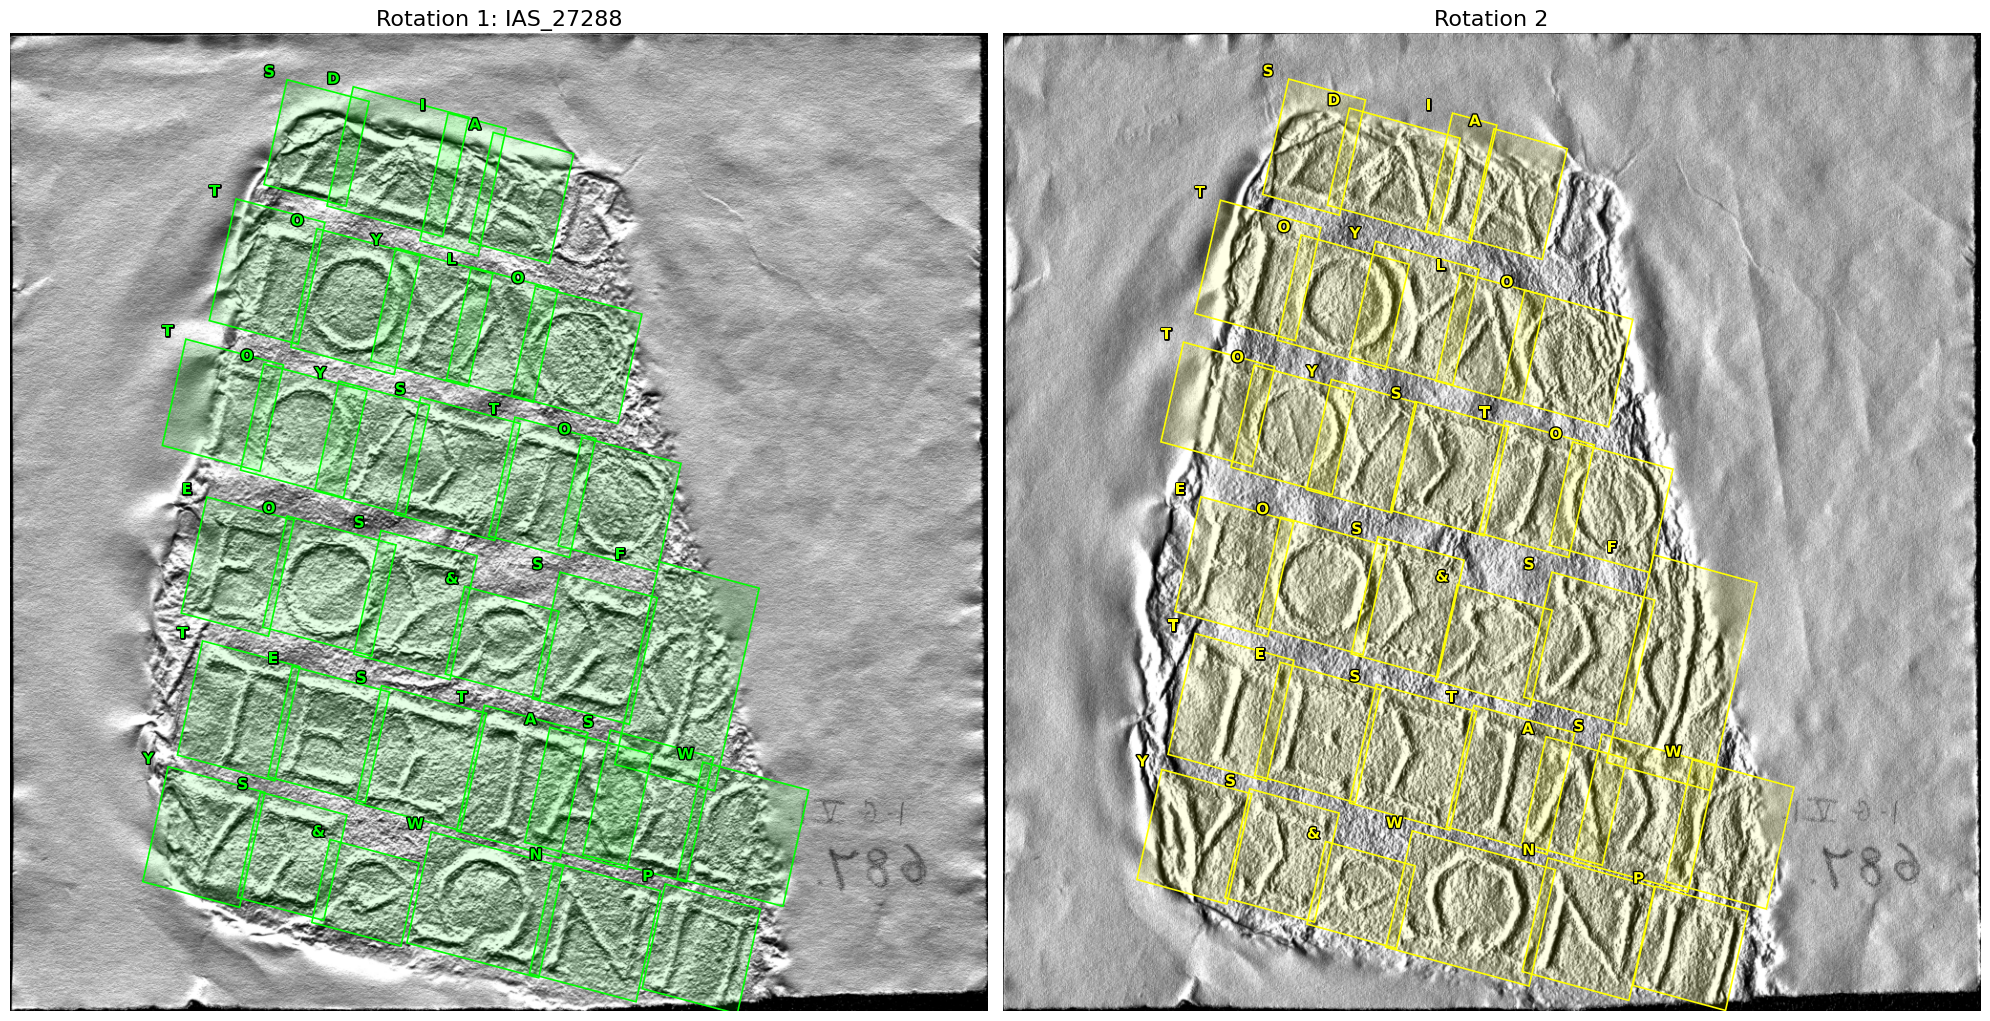

In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Polygon
import matplotlib.patheffects as pe  # Needed for the outline effect

# Display a sample
for images, metas in dataloader:
    # Find first valid sample in batch
    valid_idx = next((i for i, m in enumerate(metas) if not m['error']), None)
    
    if valid_idx is not None:
        img_6ch = images[valid_idx]
        m = metas[valid_idx]

        # testing part here: hardcoding
        target_id = "IAS_27288"

        for i in range(len(dataset)):
            _, m = dataset[i]
            if m['id'] == target_id:
                idx = i
                break

        img_6ch, m = dataset[idx]


        # hardcoding end here
        
        # Scale factors for polygons
        sw = IMG_SIZE / m['orig_size'][0]
        sh = IMG_SIZE / m['orig_size'][1]

        fig, ax = plt.subplots(1, 2, figsize=(20, 12))
        
        # ---------- Rotation 1 ----------
        ax[0].imshow(img_6ch[:3].permute(1, 2, 0).numpy())
        ax[0].set_title(f"Rotation 1: {m['id']}", fontsize=16)
        ax[0].axis("off")

        for poly, label in zip(m['boxes1'], m['labels1']):
            scaled_poly = [(p[0]*sw, p[1]*sh) for p in poly]
            
            # Draw Polygon
            ax[0].add_patch(
                Polygon(scaled_poly, closed=True, fill=True,
                        edgecolor='lime', facecolor=(0,1,0,0.1), lw=1.2)
            )

            # Find top-left corner for label placement (min x, min y)
            x_min = min(p[0] for p in scaled_poly)
            y_min = min(p[1] for p in scaled_poly)

            # Print label at top-left
            # va='bottom' puts the text ABOVE the line
            ax[0].text(
                x_min, y_min, str(label),
                color='lime',
                fontsize=11,
                ha='left', va='bottom',
                weight='bold',
                path_effects=[pe.withStroke(linewidth=2, foreground='black')]
            )

        # ---------- Rotation 2 ----------
        ax[1].imshow(img_6ch[3:].permute(1, 2, 0).numpy())
        ax[1].set_title("Rotation 2", fontsize=16)
        ax[1].axis("off")

        for poly, label in zip(m['boxes2'], m['labels2']):
            scaled_poly = [(p[0]*sw, p[1]*sh) for p in poly]
            
            ax[1].add_patch(
                Polygon(scaled_poly, closed=True, fill=True,
                        edgecolor='yellow', facecolor=(1,1,0,0.1), lw=1.2)
            )

            # Find top-left corner
            x_min = min(p[0] for p in scaled_poly)
            y_min = min(p[1] for p in scaled_poly)

            ax[1].text(
                x_min, y_min, str(label),
                color='yellow',
                fontsize=11,
                ha='left', va='bottom',
                weight='bold',
                path_effects=[pe.withStroke(linewidth=2, foreground='black')]
            )

        plt.tight_layout()
        plt.show()
        break